<a href="https://colab.research.google.com/github/Dgowda11/llama-spam-finetuning/blob/main/notebooks/05_base_model_baseline_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this phase we will assess how well the original, unfine-tuned Llama 3.2 3B Instruct model performs before QLoRA.

In [1]:

import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Count:", torch.cuda.device_count())

    total_memory = torch.cuda.get_device_properties(0).total_memory
    free_memory, total_memory_cuda = torch.cuda.mem_get_info()

    print(f"Total GPU Memory: {total_memory / 1024**3:.2f} GB")
    print(f"Free GPU Memory: {free_memory / 1024**3:.2f} GB")
else:
    print("GPU is not available. Check your Colab runtime settings.")


PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU Name: Tesla T4
GPU Count: 1
Total GPU Memory: 14.56 GB
Free GPU Memory: 14.46 GB


In [2]:
# install required Dependencies

%pip install -q -U transformers accelerate datasets huggingface_hub kaggle scikit-learn pandas matplotlib seaborn


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [3]:
%pip install -q --force-reinstall pandas==2.2.3 pyarrow==23.0.1

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.2.0 requires pyarrow>=24.0.0, but you have pyarrow 23.0.1 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.


In [4]:

# Clone the project repository

%cd /content

!git clone https://github.com/Dgowda11/sms-spam-llama-qlora.git /content/llama-spam-finetuning

%cd /content/llama-spam-finetuning

!ls


/content
Cloning into '/content/llama-spam-finetuning'...
remote: Enumerating objects: 96, done.
remote: Counting objects: 100% (96/96), done.
remote: Compressing objects: 100% (75/75), done.
remote: Total 96 (delta 43), reused 54 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (96/96), 622.98 KiB | 9.58 MiB/s, done.
Resolving deltas: 100% (43/43), done.
/content/llama-spam-finetuning
data  LICENSE  notebooks  README.md  requirements.txt  src


In [5]:

import torch
import transformers
import datasets
import pandas as pd
import sklearn

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("CUDA Available:", torch.cuda.is_available())


PyTorch: 2.14.1+cu130
Transformers: 5.23.0
Datasets: 5.2.0
Pandas: 2.2.3
Scikit-learn: 1.9.1
CUDA Available: True


In [6]:
#Authenticate the Hugging Face
from google.colab import userdata
from huggingface_hub import login

HF_TOKEN = userdata.get("HF_TOKEN")

login(token=HF_TOKEN)

print("Hugging Face authentication successful!")

Hugging Face authentication successful!


In [7]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID
)
print("Tokenizer loaded successfully!")
print("Tokenizer:", tokenizer.__class__.__name__)
print("Vocabulary size:", tokenizer.vocab_size)
print("EOS Token:", tokenizer.eos_token)

config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

Tokenizer loaded successfully!
Tokenizer: TokenizersBackend
Vocabulary size: 128000
EOS Token: <|eot_id|>


Load the Base Model

In [8]:

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)

model.eval()

print("Base Llama model loaded successfully!")
print("Model dtype:", model.dtype)
print("Model device:", model.device)
print("Model training mode:", model.training)

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Base Llama model loaded successfully!
Model dtype: torch.float16
Model device: cuda:0
Model training mode: False


In [ ]:
# MOnitor the Resources
if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated(0) / 1024**3
    reserved = torch.cuda.memory_reserved(0) / 1024**3
    free, total = torch.cuda.mem_get_info(0)

    print(f"GPU Allocated: {allocated:.2f} GB")
    print(f"GPU Reserved: {reserved:.2f} GB")
    print(f"GPU Free: {free / 1024**3:.2f} GB")
    print(f"GPU Total: {total / 1024**3:.2f} GB")

GPU Allocated: 5.98 GB
GPU Reserved: 6.00 GB
GPU Free: 8.46 GB
GPU Total: 14.56 GB


Lets do the Zero Shot Inference

In [9]:

def predict_sms(message):

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Message: {message}"}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=10,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    prediction = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    ).strip().upper()

    # Normalize classification output
    if prediction.startswith("HAM"):
        return "ham"
    elif prediction.startswith("SPAM"):
        return "spam"
    else:
        return "unknown"


In [10]:
#Define the System Prompt
SYSTEM_PROMPT = """
You are an SMS classification assistant.

Your task is to classify SMS messages into one of two categories:
- HAM: A legitimate, normal message.
- SPAM: An unsolicited, fraudulent, promotional, or suspicious message.

Analyze the message carefully.

Respond with only one label:
HAM or SPAM.

Do not provide explanations or additional text.
"""

In [ ]:
test_messages =  [
    "Congratulations! You have won a free iPhone. Click here to claim.",
    "Hey, are we still meeting for lunch today?"
]

for message in test_messages:
  prediction = predict_sms(message)

  print("SMS:", message)
  print("Prediction:", prediction)
  print("-" * 80)

SMS: Congratulations! You have won a free iPhone. Click here to claim.
Prediction: spam
--------------------------------------------------------------------------------
SMS: Hey, are we still meeting for lunch today?
Prediction: ham
--------------------------------------------------------------------------------


Execute full Test dataset inference

In [11]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/llama-spam-finetuning")

DATA_DIR = PROJECT_ROOT / "data" / "prepared"

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

assert TRAIN_PATH.exists(), f"Missing: {TRAIN_PATH}"
assert TEST_PATH.exists(), f"Missing: {TEST_PATH}"

print("Dataset paths verified!")

Dataset paths verified!


In [12]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
import time
from tqdm.auto import tqdm

predictions = []
inference_times = []

model.eval()

for message in tqdm(test_df["message"], desc="Running baseline inference"):

    start_time = time.perf_counter()

    prediction = predict_sms(message)

    end_time = time.perf_counter()

    predictions.append(prediction)
    inference_times.append(end_time - start_time)

print("Inference completed!")
print("Total test samples:", len(test_df))
print("Total predictions:", len(predictions))


Running baseline inference:   0%|          | 0/1034 [00:00<?, ?it/s]

Inference completed!
Total test samples: 1034
Total predictions: 1034


Predition Evaluations

In [13]:
baseline_results = pd.DataFrame({
    "message": test_df["message"].values,
    "actual_label": test_df["label"].str.lower().values,
    "predicted_label": predictions,
    "inference_time": inference_times
})

baseline_results["correct"] = (
    baseline_results["actual_label"] ==
    baseline_results["predicted_label"]
)

display(baseline_results.head(10))

,message,actual_label,predicted_label,inference_time,correct
0,"Good morning, my Love ... I go to sleep now an...",ham,ham,1.207016,True
1,"And how you will do that, princess? :)",ham,ham,0.121708,True
2,Nope. Meanwhile she talk say make i greet you.,ham,spam,0.128940,False
3,Designation is software developer and may be s...,ham,spam,0.138526,False
4,Aiya we discuss later lar... Pick Ì_ up at 4 i...,ham,ham,0.086996,True
5,"Piggy, r u awake? I bet u're still sleeping. I...",ham,ham,0.098873,True
6,S but not able to sleep.,ham,ham,0.090918,True
7,Yes. Please leave at &lt;#&gt; . So that at ...,ham,ham,0.100011,True
8,hi baby im sat on the bloody bus at the mo and...,ham,ham,0.102992,True
9,Yup... Hey then one day on fri we can ask miwa...,ham,ham,0.103382,True


In [14]:
print("Actual label distribution:")
print(baseline_results["actual_label"].value_counts())

print("\nPredicted label distribution:")
print(baseline_results["predicted_label"].value_counts())

print(
    "\nUnknown predictions:",
    (baseline_results["predicted_label"] == "unknown").sum()
)

Actual label distribution:
actual_label
ham     903
spam    131
Name: count, dtype: int64

Predicted label distribution:
predicted_label
ham     524
spam    510
Name: count, dtype: int64

Unknown predictions: 0


Calculate the Evalutation metrics

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_true = baseline_results["actual_label"]
y_pred = baseline_results["predicted_label"]

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    pos_label="spam",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    pos_label="spam",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    pos_label="spam",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Accuracy:  0.6238
Precision: 0.2471
Recall:    0.9618
F1-score:  0.3931


In [16]:
print(classification_report(
    y_true,
    y_pred,
    labels=["ham", "spam", "unknown"],
    zero_division=0
))

              precision    recall  f1-score   support

         ham       0.99      0.57      0.73       903
        spam       0.25      0.96      0.39       131
     unknown       0.00      0.00      0.00         0

    accuracy                           0.62      1034
   macro avg       0.41      0.51      0.37      1034
weighted avg       0.90      0.62      0.69      1034



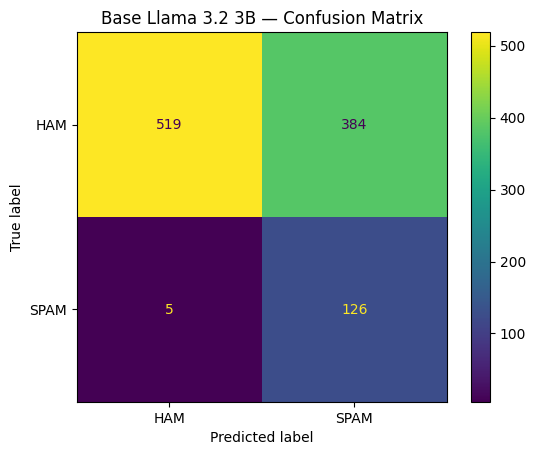

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=["ham", "spam"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["HAM", "SPAM"]
)

display_matrix.plot(values_format="d")
plt.title("Base Llama 3.2 3B — Confusion Matrix")
plt.show()

Error Analysis

In [18]:
# These are legitimate HAM messages incorrectly classified as SPAM.

false_positives = baseline_results[
    (baseline_results["actual_label"] == "ham") &
    (baseline_results["predicted_label"] == "spam")
]

print("Total False Positives:", len(false_positives))

display(
    false_positives[["message", "actual_label", "predicted_label"]]
    .head(20)
)


Total False Positives: 384


,message,actual_label,predicted_label
2,Nope. Meanwhile she talk say make i greet you.,ham,spam
3,Designation is software developer and may be s...,ham,spam
10,Just nw i came to hme da..,ham,spam
12,Nothing just getting msgs by dis name wit diff...,ham,spam
18,Neshanth..tel me who r u?,ham,spam
22,I to am looking forward to all the sex cuddlin...,ham,spam
23,Just got to &lt;#&gt;,ham,spam
25,"Also north carolina and texas atm, you would j...",ham,spam
26,Omg you can make a wedding chapel in frontierv...,ham,spam
28,\BOO BABE! U ENJOYIN YOURJOB? U SEEMED 2 B GET...,ham,spam


In [19]:

false_negatives = baseline_results[
    (baseline_results["actual_label"] == "spam") &
    (baseline_results["predicted_label"] == "ham")
]

print("Total False Negatives:", len(false_negatives))

display(
    false_negatives[["message", "actual_label", "predicted_label"]]
)


Total False Negatives: 5


,message,actual_label,predicted_label
71,Your unique user ID is 1172. For removal send ...,spam,ham
105,You will recieve your tone within the next 24h...,spam,ham
239,Customer service announcement. We recently tri...,spam,ham
326,Missed call alert. These numbers called but le...,spam,ham
329,"SMS. ac sun0819 posts HELLO:\You seem cool, wa...",spam,ham


In [20]:

import numpy as np

print("Total inference time:",
      f"{sum(inference_times):.2f} seconds")

print("Average latency:",
      f"{np.mean(inference_times):.4f} seconds")

print("Median latency:",
      f"{np.median(inference_times):.4f} seconds")

print("P95 latency:",
      f"{np.percentile(inference_times, 95):.4f} seconds")

print("Throughput:",
      f"{len(inference_times) / sum(inference_times):.2f} messages/sec")


Total inference time: 145.23 seconds
Average latency: 0.1405 seconds
Median latency: 0.1298 seconds
P95 latency: 0.2256 seconds
Throughput: 7.12 messages/sec


Base Baseline Results

In [21]:

import json
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "baseline"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Calculate metrics
metrics = {
    "model": MODEL_ID,
    "precision": "FP16",
    "test_samples": len(test_df),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "spam_precision": float(precision_score(
        y_true, y_pred, pos_label="spam", zero_division=0
    )),
    "spam_recall": float(recall_score(
        y_true, y_pred, pos_label="spam", zero_division=0
    )),
    "spam_f1": float(f1_score(
        y_true, y_pred, pos_label="spam", zero_division=0
    )),
    "unknown_predictions": int(
        (baseline_results["predicted_label"] == "unknown").sum()
    ),
    "total_inference_time_seconds": float(sum(inference_times)),
    "average_latency_seconds": float(np.mean(inference_times)),
    "throughput_samples_per_second": float(
        len(predictions) / sum(inference_times)
    )
}

# Save metrics
with open(OUTPUT_DIR / "baseline_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# Save predictions and error analysis
baseline_results.to_csv(
    OUTPUT_DIR / "baseline_predictions.csv",
    index=False
)

false_positives.to_csv(
    OUTPUT_DIR / "false_positives.csv",
    index=False
)

false_negatives.to_csv(
    OUTPUT_DIR / "false_negatives.csv",
    index=False
)

print("Baseline results saved successfully!")
print("Output directory:", OUTPUT_DIR)
print("Files:", [f.name for f in OUTPUT_DIR.iterdir()])


Baseline results saved successfully!
Output directory: /content/llama-spam-finetuning/outputs/baseline
Files: ['false_positives.csv', 'baseline_metrics.json', 'false_negatives.csv', 'baseline_predictions.csv']
